<a href="https://colab.research.google.com/github/zhixuanqin417/cs294-158-sp24-Deep-Unsupervised-Learning/blob/main/%E2%80%9C_Homework_1_Autoregressive_Models_(Solutions)_ipynb%E2%80%9D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Getting Started

## Overview
This semester, all homeworks will be conducted through Google Colab notebooks. All code for the homework assignment will be written and run in this notebook. Running in Colab will automatically provide a GPU, but you may also run this notebook locally by following [these instructions](https://research.google.com/colaboratory/local-runtimes.html) if you wish to use your own GPU.

You will save images in the notebooks to use and fill out a given LaTeX template which will be submitted to Gradescope, along with your notebook code.

## Using Colab
On the left-hand side, you can click the different icons to see a Table of Contents of the assignment, as well as local files accessible through the notebook.

Make sure to go to **Runtime -> Change runtime type** and select **GPU** as the hardware accelerator. This allows you to use a GPU. Run the cells below to get started on the assignment. Note that a session is open for a maximum of 12 hours, and using too much GPU compute may result in restricted access for a short period of time. Please start the homework early so you have ample time to work.

**If you load this notebook by clicking "Open in Colab" from github, you will need to save it to your own Google Drive to keep your work.**

## General Tips
In each homework problem, you will implement autoregressive models and run it on various datasets. Oftentime you will run it on two datasets (dataset 1 and dataset 2). In these cases, the expected outputs for dataset 1 are already provided to help as a sanity check.

Feel free to print whatever output (e.g. debugging code, training code, etc) you want, as the graded submission will be the submitted pdf with images.

After you complete the assignment, download all of the images outputted in the results/ folder and upload them to the figure folder in the given latex template.

There is a lot of freedom in this homework to design write and design your own models. Hyperparameters are given as a guide to show what worked for us, but feel free to explore and use what you find is best!

Run the cells below to download and load up the starter code.

In [3]:
!if [ -d deepul ]; then rm -Rf deepul; fi
!git clone https://github.com/rll/deepul.git
!unzip -qq deepul/homeworks/hw1/data/hw1_data.zip -d deepul/homeworks/hw1/data/
!pip install ./deepul

Cloning into 'deepul'...
remote: Enumerating objects: 270, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (50/50), done.
remote: Total 270 (delta 51), reused 32 (delta 32), pack-reused 188 (from 2)
Receiving objects: 100% (270/270), 94.71 MiB | 38.26 MiB/s, done.
Resolving deltas: 100% (100/100), done.
Processing ./deepul
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for deepul: filename=deepul-0.1.0-py3-none-any.whl size=22752 sha256=eb070851a17939d8106bd208dc7986db857122efedd2aa047b13d59aa7de2ed1
  Stored in directory: /tmp/pip-ephem-wheel-cache-aa3x0iqg/wheels/c6/11/96/9d09a4cd223b25989843669b43b3d34c4306cdeb8b562740cc
Successfully built deepul


In [4]:
import numpy as np
from deepul.hw1_helper import (
    # Q1
    visualize_q1_data,
    q1_sample_data_1,
    q1_sample_data_2,
    q1_save_results,
    # Q2
    q2a_save_results,
    q2b_save_results,
    visualize_q2a_data,
    visualize_q2b_data,
    # Q3
    q3ab_save_results,
    q3c_save_results,
    # Q4
    q4a_save_results,
    q4b_save_results,
    # Q5
    visualize_q5_data,
    q5a_save_results,
    # Q6
    visualize_q6_data,
    q6a_save_results,
)

# Question 1: 1D Data

In this question, we will train simple generative models on discrete 1D data.

Execute the cell below to visualize our datasets

Dataset 1


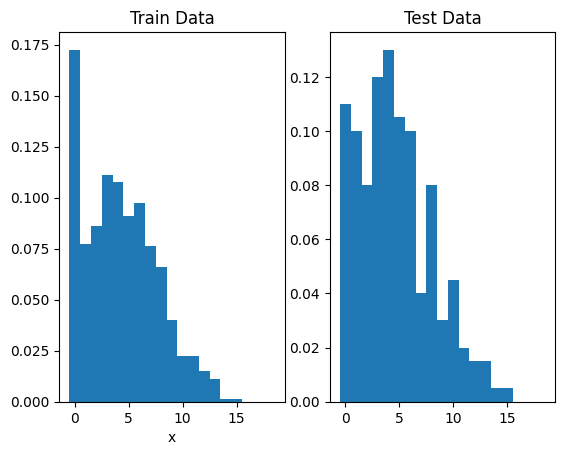

Dataset 2


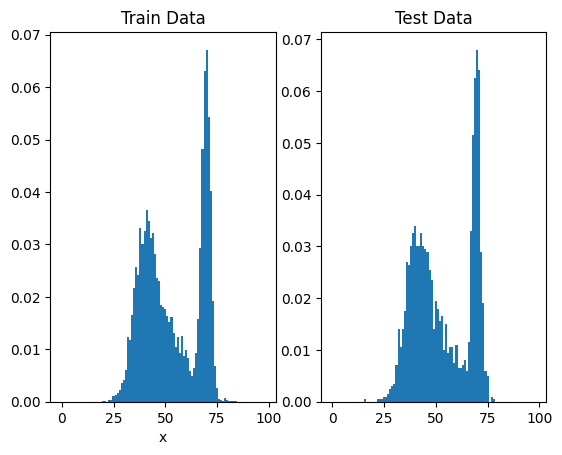

In [ ]:
visualize_q1_data(dset_type=1)
visualize_q1_data(dset_type=2)

## Part (a) Fitting a Histogram

Let $\theta = (\theta_0, \dots, \theta_{d-1}) \in \mathbb{R}^{d}$ and define the model $p_\theta(x) = \frac{e^{\theta_x}}{\sum_{x'}e^{\theta_{x'}}}$

Fit $p_\theta$ with maximum likelihood via stochastic gradient descent on the training set, using $\theta$ initialized to zero. Use your favorite version of stochastic gradient descent, and optimize your hyperparameters on a validation set of your choice.

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. Plot the model probabilities in a bar graph with $\{0,\dots,d-1\}$ on the x-axis and a real number in $[0,1]$ on the y-axis.




Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
def q1_a(train_data, test_data, d, dset_id):
  """
  train_data: An (n_train,) numpy array of integers in {0, ..., d-1}
  test_data: An (n_test,) numpy array of integers in {0, .., d-1}
  d: The number of possible discrete values for random variable x
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
             used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (d,) of model probabilities
  """
  theta = np.zeros(d)
  epochs, batch_size, lr = 30, max(1, len(train_data) // 10), 0.1

  def nll(data):
    return np.logaddexp.reduce(theta) - np.mean(theta[data])

  train_losses, test_losses = [], [nll(test_data)]
  for _ in range(epochs):
    data = np.random.permutation(train_data)
    for i in range(0, len(data), batch_size):
      batch = data[i:i + batch_size]
      train_losses.append(nll(batch))

      probs = np.exp(theta - np.logaddexp.reduce(theta))
      grad = probs - np.bincount(batch, minlength=d) / len(batch)
      theta -= lr * grad

    test_losses.append(nll(test_data))

  distribution = np.exp(theta - np.logaddexp.reduce(theta))

  return train_losses, test_losses, distribution

### Results

Once you've implemented `q1_a`, execute the cells below to visualize and save your results



Final Test Loss: 2.6224


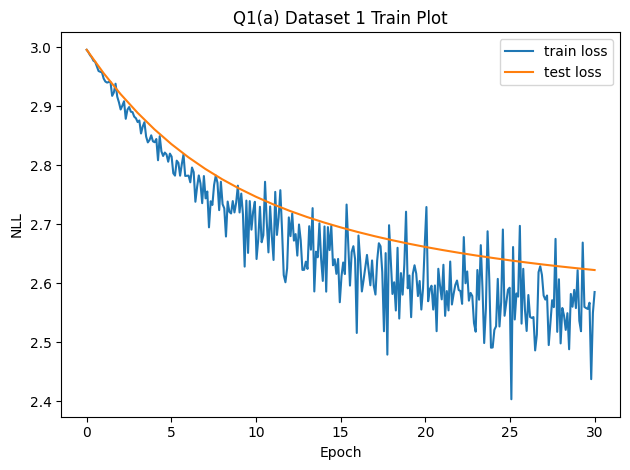

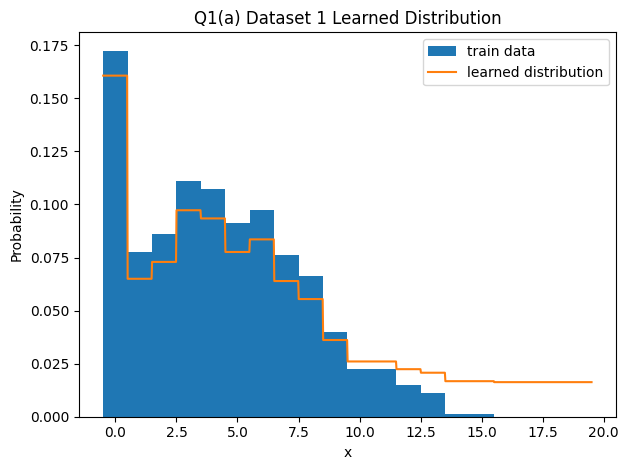

In [ ]:
q1_save_results(1, 'a', q1_a)

Final Test Loss: 4.1481


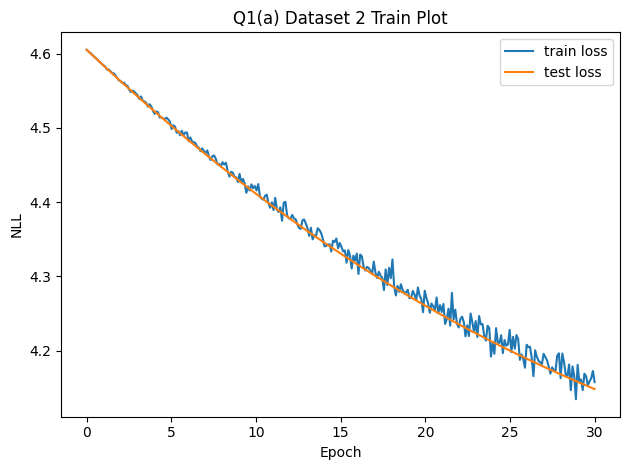

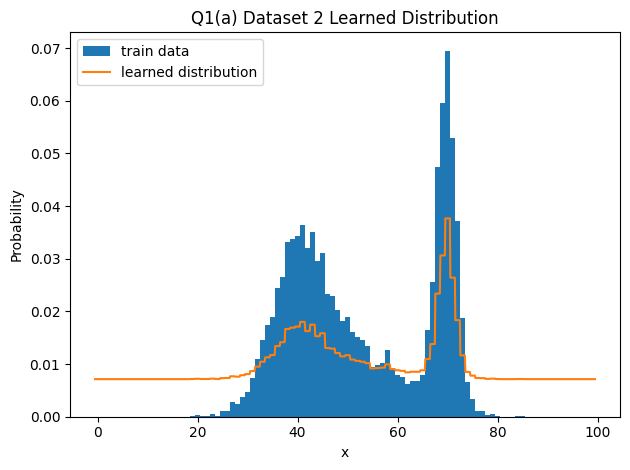

In [ ]:
q1_save_results(2, 'a', q1_a)

## Part (b) Fitting Discretized Mixture of Logistics

Let us model $p_\theta(x)$ as a **discretized** mixture of 4 logistics such that $p_\theta(x) = \sum_{i=1}^4 \pi_i[\sigma((x+0.5 - \mu_i)/s_i) - \sigma((x-0.5-\mu_i)/s_i)]$

For the edge case of when $x = 0$, we replace $x-0.5$ by $-\infty$, and for $x = 99$, we replace $x+0.5$ by $\infty$.

You may find the [PixelCNN++](https://arxiv.org/abs/1701.05517) helpful for more information on discretized mixture of logistics.

**Provide the same set of corresponding deliverables as part (a)**

Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
class DiscretizedMixtureLogistic(nn.Module):
  def __init__(self, d, num_mixtures=4):
    super().__init__()

    self.d = d
    self.num_mixtures = num_mixtures

    # Mixture weights: pi
    self.logits_pi = nn.Parameter(
        torch.zeros(num_mixtures)
    )

    # Initialize center position
    self.mu = nn.Parameter(
        torch.linspace(0, d - 1, num_mixtures)
    )

    # Initialize scales to positive values
    initial_scale = max(d / 4, 1.0)

    self.raw_scale = nn.Parameter(
        torch.full(
          (num_mixtures, ),
          float(np.log(np.expm1(initial_scale)))
        )
    )


  def log_prob(self, x):

    x = x.to(device=self.mu.device, dtype=self.mu.dtype).unsqueeze(-1)

    log_pi = F.log_softmax(self.logits_pi, dim=0)

    s = F.softplus(self.raw_scale) + 1e-6

    upper = (x + 0.5 - self.mu) / s
    lower = (x - 0.5 - self.mu) / s

    log_mass = (
        F.logsigmoid(upper)
        + F.logsigmoid(-lower)
        + torch.log(-torch.expm1(-1.0 / s))
    )

    # (-∞, 0.5)
    log_mass = torch.where(
        x == 0,
        F.logsigmoid(upper),
        log_mass
    )

    # [d - 1.5, +∞)
    log_mass = torch.where(
        x == self.d - 1,
        F.logsigmoid(-lower),
        log_mass
    )

    # [B]
    return torch.logsumexp(log_pi + log_mass, dim=-1)

  def forward(self, x):

    return self.log_prob(x).exp()

  def nll(self, x):

    return -self.log_prob(x).mean()

In [ ]:
import numpy as np
import torch
from torch.utils.data import DataLoader

def q1_b(train_data, test_data, d, dset_id):
  """
  train_data: An (n_train,) numpy array of integers in {0, ..., d-1}
  test_data: An (n_test,) numpy array of integers in {0, .., d-1}
  d: The number of possible discrete values for random variable x
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (d,) of model probabilities
  """
  num_epoches = 100
  batch_size = 128
  learning_rate = 1e-2

  device = torch.device(
      "cuda" if torch.cuda.is_available() else "cpu"
  )

  # numpy -> tensor
  train_tensor = torch.as_tensor(
      train_data, dtype=torch.long
  )
  test_tensor = torch.as_tensor(
      test_data, dtype=torch.long
  )

  train_loader = DataLoader(
      train_tensor,
      batch_size=batch_size,
      shuffle=True,
      drop_last=False
  )

  test_loader = DataLoader(
      test_tensor,
      batch_size=4096,
      shuffle=False
  )

  # initailize model and optimizer
  model = DiscretizedMixtureLogistic(d, 4).to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  # evaluate test dataset
  @torch.no_grad()
  def evaluate_test_loss():
    model.eval()
    total_nll = 0.0

    # accumulate loss of every sample
    for x_batch in test_loader:
      x_batch = x_batch.to(device)

      total_nll += (-model.log_prob(x_batch)).sum().item()
    # return mean loss of batch size samples
    return total_nll / len(test_tensor)

  train_losses = []

  # record test loss before training
  test_losses = [evaluate_test_loss()]

  # training
  for epoch in range(num_epoches):
    model.train()

    for x_batch in train_loader:
      x_batch = x_batch.to(device)

      optimizer.zero_grad()

      loss = model.nll(x_batch)
      loss.backward()

      optimizer.step()

      # every minibatch
      train_losses.append(loss.item())

    # record a test loss after a epoch
    test_losses.append(evaluate_test_loss())

  # calculate model probablity
  model.eval()

  with torch.no_grad():
    all_x = torch.arange(d, dtype=torch.long)

    distribution = model(all_x).cpu().numpy()

  return train_losses, test_losses, distribution

### Results

Once you've implemented `q1_b`, execute the cells below to visualize and save your results



Final Test Loss: 2.5492


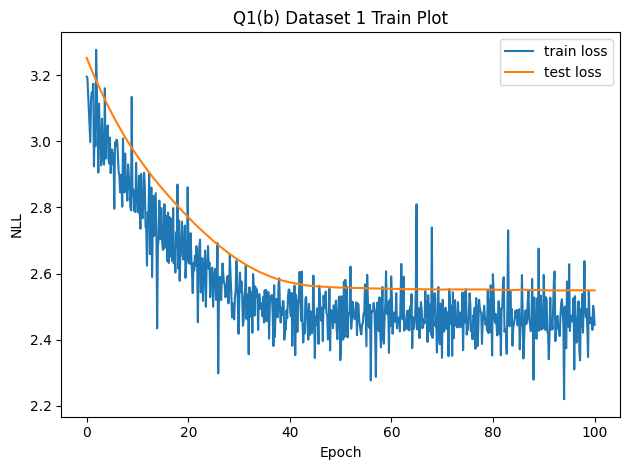

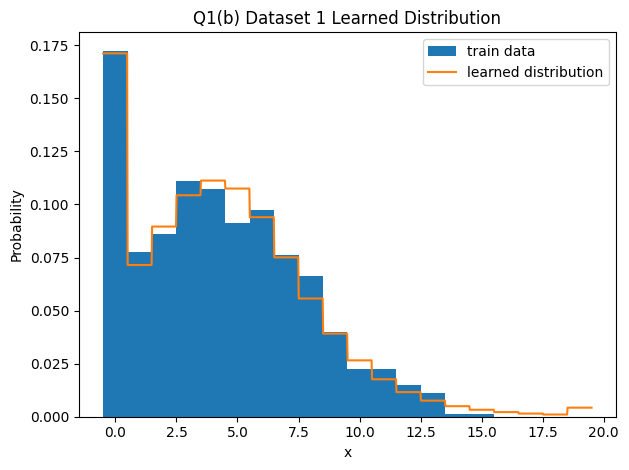

In [ ]:
q1_save_results(1, 'b', q1_b)

In [ ]:
q1_save_results(2, 'b', q1_b)

KeyboardInterrupt: 

# Question 2 PixelCNNs

Now, you will train more powerful PixelCNN models on the shapes dataset and MNIST. In addition, we will extend to modeling colored datasets.

Run the cell below to visualize the two datasets binary datasets

In [ ]:
visualize_q2a_data(1)
visualize_q2a_data(2)

## Part (a) PixelCNN on Shapes and MNIST
In this part, implement a simple PixelCNN architecture to model binary MNIST and shapes images (same as Q2(b), but with a PixelCNN).

We recommend the following network design:
* A $7 \times 7$ masked type A convolution
* $5$ $7 \times 7$ masked type B convolutions
* $2$ $1 \times 1$ masked type B convolutions
* Appropriate ReLU nonlinearities in-between
* 64 convolutional filters

And the following hyperparameters:
* Batch size 128
* Learning rate $10^{-3}$
* 10 epochs
* Adam Optimizer (this applies to all PixelCNN models trained in future parts)

Your model should output logits, after which you could apply a sigmoid over 1 logit, or a softmax over two logits (either is fine). It may also help to scale your input to $[-1, 1]$ before running it through the network.

Training on the shapes dataset should be quick, and MNIST should take around 10 minutes

Checkout the Paper for more details: https://arxiv.org/abs/1601.06759

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model



Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
class MaskedConv2d(nn.Conv2d):
  def __init__(self, in_channels, out_channels, kernel_size, mask_type):
    assert mask_type in ("A", "B")
    assert kernel_size % 2 == 1

    super().__init__(
      in_channels, out_channels, kernel_size,
      padding=kernel_size // 2
    )

    mask = torch.ones_like(self.weight)
    center = kernel_size // 2

    # make 0 pixels
    mask[:, :, center + 1:, :] = 0
    mask[:, :, center, center + 1:] = 0

    # make 0 pixels of special type Conv2d
    if mask_type == "A":
      mask[:, :, center, center] = 0

    self.register_buffer("mask", mask)

  def forward(self, x):
    weight = self.weight * self.mask
    return F.conv2d(
      x, weight, self.bias,
      self.stride, self.padding,
      self.dilation, self.groups
    )

In [ ]:
conv_a = MaskedConv2d(1, 64, 7, "A")
conv_b = MaskedConv2d(64, 64, 7, "B")

print("Type A mask:")
print(conv_a.mask[0, 0])

print("\nType B mask:")
print(conv_b.mask[0, 0])


In [ ]:
class PixelCNN(nn.Module):
  def __init__(self, hidden_channels=64):
    super().__init__()

    layers = []

    # layer 1: type A
    layers.append(
      MaskedConv2d(1, hidden_channels, 7, "A")
    )
    layers.append(nn.ReLU())

    # (layers 2:6): type B
    for _ in range(5):
      layers.append(
        MaskedConv2d(
          hidden_channels, hidden_channels, 7, "B"
        )
      )
      layers.append(nn.ReLU())

    # (layer 7:8) : type B
    for _ in range(2):
      layers.append(
          MaskedConv2d(
            hidden_channels, hidden_channels, 1, "B"
          )
      )
      layers.append(nn.ReLU())

    self.features = nn.Sequential(*layers)

    # map hidden_channels to one logit
    self.output = nn.Conv2d(
      hidden_channels, 1, kernel_size = 1
    )

  def forward(self, x):
    h = self.features(x)
    logits = self.output(h)
    return logits


In [ ]:

model = PixelCNN(hidden_channels=64)

# 模拟 2 张 28×28 的二值图像
x = torch.randint(0, 2, (2, 1, 28, 28)).float()

logits = model(x)

print("Input shape:", x.shape)
print("Output shape:", logits.shape)
print("Parameter count:",
      sum(p.numel() for p in model.parameters()))
print("Output range:", logits.min().item(), logits.max().item())


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q2_a(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, 1) uint8 numpy array of binary images with values in {0, 1}
  test_data: A (n_test, H, W, 1) uint8 numpy array of binary images with values in {0, 1}
  image_shape: (H, W), height and width of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (100, H, W, 1) of samples with values in {0, 1}
  """
  H, W = image_shape
  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  # 1. Convert NHWC to PyTorch's NCHW format
  train_tensor = torch.as_tensor(
      train_data, dtype=torch.float32
  ).permute(0, 3, 1, 2).contiguous()

  test_tensor = torch.as_tensor(
      test_data, dtype=torch.float32
  ).permute(0, 3, 1, 2).contiguous()

  train_loader = DataLoader(
      TensorDataset(train_tensor), batch_size=128, shuffle=True
  )
  test_loader = DataLoader(
      TensorDataset(test_tensor), batch_size=128, shuffle=False
  )

  # 2. Initialize model, loss and optimizer
  model = PixelCNN(hidden_channels=64).to(device)
  criterion = nn.BCEWithLogitsLoss(reduction="sum")
  optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

  epochs = 10

  train_losses = []
  test_losses = []

  # 3. Evaluation function
  def evaluate():
    model.eval()

    total_loss = 0.0
    total_pixels = 0

    with torch.no_grad():
      for (x,) in test_loader:
        x = x.to(device)

        # scale input from [0,1] to [-1,1]
        x_input = x * 2.0 - 1.0

        logits = model(x_input)

        loss = criterion(logits, x)

        total_loss += loss.item()
        total_pixels += x.numel()

    return total_loss / total_pixels

  # Evaluate before training
  test_losses.append(evaluate())

  # 4. Training
  for epoch in range(epochs):
    model.train()

    for (x,) in train_loader:

      x = x.to(device)

      # Scale input to [-1, 1]
      x_input = x * 2.0 - 1.0

      # Forward pass
      logits = model(x_input)

      # Average NLL per pixel
      loss_sum = criterion(logits, x)
      loss = loss_sum / x.numel()

      # Backpropagation
      optimizer.zero_grad()

      loss.backward()

      optimizer.step()

      # Record training loss for this minibatch
      train_losses.append(loss.item())

    # Evaluate after each epoch
    test_loss = evaluate()
    test_losses.append(test_loss)

    print(
      f"Epoch [{epoch + 1}/{epochs}] "
      f"Train NLL: {np.mean(train_losses[-len(train_loader):]):.4f} "
      f"Test NLL: {test_loss:.4f}"
    )


  # 5. Autoregressive sampling
  model.eval()

  num_samples = 100

  # Initialize all pixels to zero
  samples = torch.zeros(
      num_samples, 1, H, W,
      dtype = torch.float32,
      device=device
  )

  with torch.no_grad():

    # Raster scan: top to bottom, left to right
    for i in range(H):
      for j in range(W):

        # Scale current partially generated images
        x_input = samples * 2.0 - 1.0

        # Predict logits
        logits = model(x_input)

        # Get the probablity of pixel (i, j) being 1
        prob = torch.sigmoid(logits[:, 0, i, j])

        # Sample from Bernoulli distribution
        pixel = torch.bernoulli(prob)

        # Update the current pixel
        samples[:,0,i,j] = pixel

  # Convert NCHW back to NHWC
  samples = (
    samples.permute(0, 2, 3, 1)
    .cpu()
    .numpy()
    .astype(np.uint8)
  )


  # 6. Return results
  train_losses = np.array(train_losses)
  test_losses = np.array(test_losses)



  return train_losses, test_losses, samples

### Results

Once you've implemented `q2_a`, execute the cells below to visualize and save your results



In [ ]:
q2a_save_results(1, q2_a)

In [ ]:
q2a_save_results(2, q2_a)

## Part (b) PixelCNN on Colored Shapes and MNIST: Independent Color Channels

For the next part, we'll work with color images (shapes and MNIST). Run the cell below to visualize the dataset.

In [ ]:
visualize_q2b_data(1)
visualize_q2b_data(2)

Now, implement a PixelCNN to support RGB color channels (or augment your existing implementation). **First, implement a PixelCNN that assumes color channels as independent.** More formally, we model the following parameterized distribution:

$$p_\theta(x) = \prod_{i=1}^{HW}\prod_{c=1}^C p_\theta(x_i^c | x_{<i})$$

Here are some tips that you may find useful for designing and training these models:
* You will need a 4-way softmax for every prediction, as opposed to a 256-way softmax in the PixelCNN paper, since the dataset is quantized to two bits per color channel
* You can set the number of filters for each convolutions to 120. You can use the ReLU nonlinearity throughout.
* Use a stack of 8 residual block architecture from [Figure 5](https://arxiv.org/abs/1601.06759) but with 7 x 7 masked convolutions in the middle instead of 3 x 3 masked convolutions
* Consider using [layer normalization](https://arxiv.org/abs/1607.06450) to improve performance. However, be careful to maintain the autoregressive property.
* With a learning rate of $10^{-3}$ and a batch size of 128, it should take a few minutes to run on the shapes dataset, and about 50-60 minutes on MNIST.

**You will provide these deliverables**


1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model



Fill out the function below and return the necessary arguments. Feel free to create more cells if need be.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class MaskedConv2d(nn.Conv2d):
  def __init__(self, mask_type, in_channels, out_channels, kernel_size, padding=0):
    if mask_type not in ("A", "B"):
      raise ValueError("kernel_size must be odd")

    # initialize weights and bias of normal conv2d
    super().__init__(in_channels=in_channels, out_channels=out_channels, kernel_size=kernel_size, padding=padding)

    # create initial mask
    mask = torch.ones_like(self.weight)
    center = kernel_size // 2

    # make mask perfect
    mask[:, :, center + 1:, :] = 0
    mask[:, :, center, center+1: ] = 0

    if mask_type == "A":
      mask[:, :, center, center] = 0

    self.register_buffer("mask", mask)


  def forward(self, x):
    effective_weight = self.weight * self.mask

    return F.conv2d(x, effective_weight, self.bias, stride=self.stride, padding=self.padding)


In [ ]:
layer = MaskedConv2d(
    mask_type="A",
    in_channels=3,
    out_channels=120,
    kernel_size=7,
    padding=3
)

x = torch.randn(2, 3, 8, 8)
y = layer(x)

print(layer.weight.shape)
print(y.shape)
print(layer.mask[0, 0].int())

In [ ]:
class ResidualBlock(nn.Module):
  def __init__(self, channels=120):
    super().__init__()

    hidden_channels = channels // 2

    # kernel_size = 1
    self.conv1 = MaskedConv2d(mask_type="B", in_channels=channels, out_channels=hidden_channels, kernel_size=1, padding=0)

    # kernel_size = 7
    self.conv2 = MaskedConv2d(mask_type="B", in_channels=hidden_channels, out_channels=hidden_channels, kernel_size=7, padding=3)

    # kernel_size = 1
    self.conv3 = MaskedConv2d(mask_type="B", in_channels=hidden_channels, out_channels=channels, kernel_size=1, padding=0)

  def forward(self, x):
    residual = x

    out = F.relu(x)
    out = self.conv1(out)

    out = F.relu(out)
    out = self.conv2(out)

    out = F.relu(out)
    out = self.conv3(out)

    return residual + out


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class RGBPixelCNN(nn.Module):
  def __init__(self):
    super().__init__()

    # 1. Initial Mask A Convolution
    self.input_conv = MaskedConv2d("A", in_channels=3, out_channels=120, kernel_size=7, padding=3)

    # 2. Stack 8 Residual Blocks
    self.res_blocks = nn.Sequential(*[ResidualBlock(channels=120) for _ in range(8)])

    # 3. Output Convolution
    # RGB channels * 3 classes = 12 output channels
    self.output_conv = nn.Conv2d(in_channels=120, out_channels=12, kernel_size=1)


  def forward(self, x):

    # x: [B, 3, H, W]

    # 1. Initial Mask A Convolution
    x = self.input_conv(x)

    # 2. Residual Blocks
    x = self.res_blocks(x)

    # 3. ReLu + Output Convolution
    x = F.relu(x)
    x= self.output_conv(x)

    # 4. Reshape output Logits
    B, _, H, W =x.shape

    x = x.reshape(B, 3, 4, H, W)

    # [B, 3, 4, H, W] -> [B, 4, 3, H, W]
    x = x.permute(0, 2, 1, 3, 4)

    return x


In [ ]:
model = RGBPixelCNN()

# initialize
x = torch.randn(2, 3, 28, 28)

# forward
logits = model(x)

print("input: ", x.shape)
print("output: ", logits.shape)

# check output
assert logits.shape == (2, 4, 3, 28, 28)

print("Forward pass successful!")


In [ ]:
def compute_loss(model, images):
  """
  Compute average negative log-likelihood

  Args:
    model: RGBPixerl
    images: [B, 3, H, W], quantized values in (0, 1, 2, 3)

  Returns:
    loss: scalar average NLL
  """

  # 1. Convert input to float for Conv2d
  x = images.float()

  # 2. Convert target to long for CrossEntropyLoss
  target = images.long()

  # 3. Forward
  logits = model(x)

  # logits: [B, 4, 3, H, W]
  # targets: [B, 3, H, W]

  # 4. Compute average nagative log-likelihood
  loss = F.cross_entropy(logits, target, reduction='mean')

  return loss


def evaluate(model, test_loader, device):

  model.eval()

  total_nll = 0.0
  total_dims = 0

  with torch.no_grad():

    for batch in test_loader:

      images = batch[0] if isinstance(batch, (tuple, list)) else batch

      images = images.to(device)

      x = images.float()
      target = images.long()

      logits = model(x)

      # sum all negative log-likelihoods

      loss = F.cross_entropy(logits, target, reduction='sum')

      total_nll += loss.item()

      total_dims += target.numel()


    # Average NLL per dimension
    test_nll = total_nll /total_dims

    return test_nll


def train_model(model, train_loader, test_loader, device, num_epochs):
  # 1. Move model to device
  model = model.to(device)

  # 2. Initialize Adam optimzier
  optimizer = torch.optim.Adam(model.parameters(), lr = 1e-3)

  # record training and testing NLL
  train_nll_history = []
  test_nll_history = []

  # 3. start training
  for epoch in num_epochs:

    model.train()

    epoch_total_nll = 0.0
    epoch_total_dims = 0

    for batch in train_loader:
      # extract images

      images = batch[0] if isinstance(batch, (tuple, list)) else batch

      images = images.to(device)

      # Convert images to input and target
      x = image.float()
      target = images.long()

      # Clear previous gradients
      optimizer.zero_grad()

      # Forward pass
      logits = model(x)

      # Compute average NLL
      loss = F.cross_entropy(logits, target, reduction='mean')

      # Backward parameters
      loss.backward()

      # Update parameters
      optimizer.step()

      # Record NLL for every minibatch
      train_nll_history.append(loss.item())

      # Accumulate epoch statistics
      epoch_total_nll += loss.item() * target.numel()
      epoch_total_dims += target.numel()

    # Average training NLL for this epoch
    train_epoch_nll = epoch_total_nll / epoch_total_dims

    # Evaluate on the entire test set
    test_epoch_nll = evaluate(model, test_loader, device)

    test_nll_history.append(test_epoch_nll)

    print(
      f"Epoch [{epoch + 1}/{num_epochs}] "
      f"Train NLL: {train_epoch_nll:.4f} "
      f"Test NLL: {test_epoch_nll:.4f}"
    )
  return train_nll_history, test_nll_history




In [ ]:
# Create model
model = RGBPixelCNN()

# Create a random quantized RGB image
images = torch.randint(
    0, 4,
    (2, 3, 28, 28)
)

# Compute loss
loss = compute_loss(model, images)

print("Loss:", loss.item())
print("Loss shape:", loss.shape)

In [ ]:
def q2_b(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: (H, W, C), height, width, and # of channels of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (100, H, W, C) of samples with values in {0, 1, 2, 3}
  """

  def evaluate_pixelcnn(model, test_loader, device):
    """
    Assume test_loader's type is TensorDataset
    """
    model.eval()

    total_nll = 0.0
    total_dims = 0

    with torch.no_grad():
      for (images, ) in test_loader:

        images = images.to(device)
        x = images.float()
        targets = images.long()

        logits = model(x)

        loss = F.cross_entropy(logits, targets, reduction="sum")

        total_nll += loss.item()
        total_dims += targets.numel()
    return (total_nll / total_dims)

  def sample_pixelcnn(model, image_shape, device, n_samples=100):

    H, W, C = image_shape
    model.eval()

    model_device = next(model.parameters()).device

    # Initialize empty images
    generated = torch.zeros(n_samples, C, H, W, dtype=torch.float32, device=model_device)


    with torch.no_grad():
      for i in range(H):
        for j in range(W):

          logits = model(generated)

          # Extract current pixel logits
          # [N, 4, 3, H, W] -> [N, 4, 3]
          pixel_logits = logits[:, :, :, i, j]

          # [N, 4, 3] -> [N, 3, 4]
          # put the 4 classes in the lass dimension
          pixel_logits = pixel_logits.permute(0, 2, 1)

          # Sample R, G, B independtly
          pixel_samples = torch.distributions.Categorical(logits=pixel_logits).sample()

          # Check shape
          assert pixel_samples.shape == (n_samples, 3)

          # FIll in the generated pixel
          generated[:, :, i, j] = pixel_samples.float()


    # Convert NCHW -> NHWC
    samples = generated.permute(0, 2, 3, 1)

    return samples.cpu().numpy().astype(np.uint8)


  batch_size = 128
  learning_rate = 1e-3
  num_epochs = 10

  H, W, C = image_shape

  assert dset_id in [1, 2]
  assert C == 3

  assert tuple(train_data.shape[1:]) == tuple(image_shape)
  assert tuple(test_data.shape[1:]) == tuple(image_shape)

  assert train_data.min() >= 0 and train_data.max() <= 3
  assert test_data.min() >= 0 and test_data.max() <= 3

  # 2. Prepare Dataset

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  # NHWC -> NCHW

  train_tensor = torch.from_numpy(np.ascontiguousarray(train_data.transpose(0, 3, 1, 2)))

  test_tensor = torch.from_numpy(np.ascontiguousarray(test_data.transpose(0, 3, 1, 2)))

  train_loader = DataLoader(TensorDataset(train_tensor), batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=(device.type == "cuda"))

  test_loader = DataLoader(TensorDataset(test_tensor), batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=(device.type == "cuda"))

  # Initialize model
  model = RGBPixelCNN().to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

  # Evaluate Initial Test NLL

  test_losses = []

  initial_test_nll = evaluate_pixelcnn(model, test_loader, device)

  test_losses.append(initial_test_nll)

  print(f"Initial Test NLL: {initial_test_nll:.4f}")

  # Training
  train_losses = []

  for epoch in range(num_epochs):

    model.train()

    epoch_total_nll = 0.0
    epoch_total_dims = 0

    for (images, ) in train_loader:
      images = images.to(device, non_blocking=True)

      x = images.float()
      target = images.long()

      optimizer.zero_grad(set_to_none=True)

      logits = model(x)

      loss = F.cross_entropy(logits, target, reduction="mean")

      loss.backward()

      optimizer.step()

      train_losses.append(loss.item())

      epoch_total_nll += loss.item() * target.numel()
      epoch_total_dims += target.numel()


    # Average training NLL
    train_epoch_nll = (epoch_total_nll / epoch_total_dims)

    # Evaulate entire test set
    test_epoch_nll = evaluate_pixelcnn(model, test_loader, device)

    test_losses.append(test_epoch_nll)

    print(
      f"Epoch [{epoch + 1}/{num_epochs}] "
      f"Train NLL: {train_epoch_nll:.4f} "
      f"Test NLL: {test_epoch_nll:.4f}"
    )

  samples = sample_pixelcnn(
      model,
      image_shape,
      device,
      n_samples=100
  )

  train_losses = np.asarray(
      train_losses,
      dtype=np.float32
  )

  test_losses = np.asarray(
      test_losses,
      dtype=np.float32
  )

  return train_losses, test_losses, samples

### Results

Once you've implemented `q2_b`, execute the cells below to visualize and save your results



In [ ]:
q2b_save_results(1, 'b', q2_b)

In [ ]:
q2b_save_results(2, 'b', q2_b)

# Question 3: Causal Transformer - iGPT

Now we will move onto the current most popular and widespread autoregressive model, the transformer.

## Part (a) Autoregressive Transformer on Shapes and MNIST
In this part, implement a simple Autoregressive Transformer to model binary MNIST and shapes images (same as Q2(a), but with a Transformer).

Some additional notes about your transformer implementation:
 * iGPT uses learned positional encodings. We recommend to use those here as well. However, you may also use sinusoidal positional encodings if you wish (see the [Attention is All You Need](https://arxiv.org/abs/1706.03762) paper)
 * Autoregressive transformer always predicts the **next** token, give prior tokens. iGPT has a special **\<bos\>** or beginning of sequence token at the start of every sequence every image. Make sure to include this in your implementation as well. You can generate unconditional sample by conditioning with the **\<bos\>** token.
 * While dropout is a common feature in transformer models, you do not need to add it (but may if you wish!).
 * Prebuilt transformers exist in some frameworks (i.e. pytorch). Don't just use an off the shelf implementation as the point of the exercise is to better understand the transformer architecture. Building the transformer from the ground up (use primitives such as Linear/Dense layers, LayerNorm, GeLU, Embedding)
 * Learning rate warmup and cos learning rate decay are often used when training transformers to improve training stability and improve performance. See if this helps your model! Try 1000 steps of warmup with a cosine learning rate decay.

Paper references
* [Attention Is All You Need](https://arxiv.org/abs/1706.03762)
* [Generative Pretraining from Pixels](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)
* [Language Models are Unsupervised Multitask Learners](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)

We recommend the following network design parameters:
* $d_{model}$: 128
* heads: 4
* layers: 2
* GeLU nonlinearities

And the following hyperparameters:
* Batch size: 64 or 32 or 16 (whichever fits in your GPU)
* Learning rate: $10^{-3}$
* 15 epochs or more
* Adam Optimizer (this applies to all Transformers models trained in future parts)

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 100 samples from the final trained model



In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

def prepare_data(date):
  """
  data: (N, H, W, 1), uint8, values in {0, 1}
  return (N, H*W), uint8
  """
  data = torch.from_numpy(data)

  data = data.reshape(data.shape[0], -1)

  return data

In [ ]:
def make_autoregressive_input(pixels, device):

    # 确保 pixels 在指定设备上
    pixels = pixels.to(
        device=device,
        dtype=torch.long
    )

    batch_size = pixels.shape[0]

    # BOS 也放在 pixels 所在的设备上
    bos = torch.full(
        (batch_size, 1),
        2,
        dtype=torch.long,
        device=pixels.device
    )

    # BOS + 原始像素（去掉最后一个）
    input_ids = torch.cat(
        [bos, pixels[:, :-1]],
        dim=1
    )

    targets = pixels

    return input_ids, targets

In [ ]:
pixels = torch.tensor([
    [1, 0, 0, 1],
    [0, 1, 1, 0]
])

input_ids, targets = make_autoregressive_input(
    pixels, device="cpu"
)

print("Input:")
print(input_ids)

print("Targets:")
print(targets)

Input:
tensor([[2, 1, 0, 0],
        [2, 0, 1, 1]])
Targets:
tensor([[1, 0, 0, 1],
        [0, 1, 1, 0]])


In [ ]:
class CausalSelfAttention(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    assert d_model % num_heads == 0

    self.d_model = d_model
    self.num_heads = num_heads

    # single head
    self.head_dim = d_model // num_heads

    # Q, K, V
    self.q_proj = nn.Linear(d_model, d_model)
    self.k_proj = nn.Linear(d_model, d_model)
    self.v_proj = nn.Linear(d_model, d_model)

    # output head
    self.out_proj = nn.Linear(d_model, d_model)

    # mask
    mask = torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1)

    self.register_buffer("causal_mask", mask)

  def forward(self, x):

    B, L, D = x.shape

    # 1. Q, K, V
    q = self.q_proj(x)
    k = self.k_proj(x)
    v = self.v_proj(x)

    # 2.Multi-Head
    q = q.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    k = k.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    v = v.view(B, L, self.num_heads, self.head_dim).transpose(1, 2)

    # 3. Calculate Attention Score
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)

    # 4. Add Mask
    mask = self.causal_mask[:L, :L]

    scores = scores.masked_fill(mask, float("-inf"))

    # 5. Softmax
    attn_weights = torch.softmax(scores, dim=-1)

    # 6. Attention Weight
    out = torch.matmul(attn_weights, v)

    # 7. Merge head
    out = out.transpose(1, 2).contiguous()

    out = out.view(B, L, D)

    # 8. outhead
    out = self.out_proj(out)

    return out




In [ ]:
B = 2
L = 784
D = 128

x = torch.randn(B, L, D)

attention = CausalSelfAttention(
    d_model=128,
    num_heads=4,
    max_seq_len=784
)

y = attention(x)

print("Input shape:", x.shape)
print("Output shape:", y.shape)

Input shape: torch.Size([2, 784, 128])
Output shape: torch.Size([2, 784, 128])


In [ ]:
class TransformerBlock(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    self.ln1 = nn.LayerNorm(d_model)

    # Multi-Head Causal Self-Attention
    self.attention = CausalSelfAttention(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len)

    self.ln2 = nn.LayerNorm(d_model)

    # FNN
    self.mlp = nn.Sequential(nn.Linear(d_model, 4 * d_model), nn.GELU(), nn.Linear(4 * d_model, d_model))

  def forward(self, x):

    # 1. Pre-LN + Attention + Residual
    x = x + self.attention(self.ln1(x))

    # 2. Pre-LN + FFN + Residual
    x = x + self.mlp(self.ln2(x))

    return x

In [ ]:
# Test Transformer Block
B = 2
L = 784
D = 128

x = torch.randn(B, L, D)

block = TransformerBlock(
    d_model=128,
    num_heads=4,
    max_seq_len=784
)

y = block(x)

print("Input:", x.shape)
print("Output:", y.shape)

# Test gradient
x = torch.randn(
    2, 784, 128,
    requires_grad=True
)

y = block(x)

loss = y.mean()

loss.backward()

print("Input gradient exists:", x.grad is not None)
print(
    "Attention gradient exists:",
    block.attention.q_proj.weight.grad is not None
)

Input: torch.Size([2, 784, 128])
Output: torch.Size([2, 784, 128])
Input gradient exists: True
Attention gradient exists: True


In [ ]:
class AutoregressiveTransformer(nn.Module):

  def __init__(self, max_seq_len=784, d_model=128, num_heads=4, num_layers=2):

    super().__init__()

    self.max_seq_len = max_seq_len

    # Token Embedding
    self.token_embedding = nn.Embedding(num_embeddings=3, embedding_dim=d_model)

    # Learned Positional Embedding
    self.position_embedding = nn.Embedding(num_embeddings=max_seq_len, embedding_dim=d_model)

    # Transformer Blocks
    self.blocks = nn.ModuleList([TransformerBlock(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len) for _ in range(num_layers)])

    # Final LayerNorm
    self.ln_f = nn.LayerNorm(d_model)

    # Output Head
    self.head = nn.Linear(d_model, 2)

  def forward(self, input_ids):

    B, L = input_ids.shape

    assert L <= self.max_seq_len

    # Token Embedding
    token_emb = self.token_embedding(input_ids)

    # Position Embedding
    positions = torch.arange(L, device=input_ids.device)
    pos_emb = self.position_embedding(positions)

    # Combine token and position embeddings
    x = token_emb + pos_emb

    # Transformer Blocks
    for block in self.blocks:
      x = block(x)

    # Final LayerNorm
    x = self.ln_f(x)

    # Output
    logits = self.head(x)

    return logits


In [ ]:
@torch.no_grad()
def evaluate_nll(model, test_loader, device):

  model.eval()

  total_nll = 0.0
  total_dim = 0

  for (pixels, ) in test_loader:

    pixels = pixels.to(device, dtype=torch.long)

    # Construct input
    input_ids, targets = make_autoregressive_input(pixels, device)

    # Forward
    logits = model(input_ids)

    # nll
    loss_sum = F.cross_entropy(
    logits.reshape(-1, 2),
    targets.reshape(-1),
    reduction="sum"
)

    total_nll += loss_sum.item()

    # dim
    total_dim += targets.numel()


  test_nll = total_nll / total_dim

  return test_nll


In [ ]:
def train_autoregressive_transformer(train_data, test_data, image_shape, num_epoch=15, batch_size=16, lr=1e-3, d_model=128, num_heads=4, num_layers=2):

  device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

  max_seq_len = int(np.prod(image_shape))

  train_pixels = torch.as_tensor(train_data).reshape(len(train_data), -1).long()
  test_pixels = torch.as_tensor(test_data).reshape(len(test_data), -1).long()

  train_loader = DataLoader(TensorDataset(train_pixels), batch_size=batch_size, shuffle=True)

  test_loader = DataLoader(TensorDataset(test_pixels), batch_size=batch_size, shuffle=False)

  model = AutoregressiveTransformer(max_seq_len=max_seq_len, d_model=d_model, num_heads=num_heads, num_layers=num_layers).to(device)

  optimizer = torch.optim.Adam(model.parameters(), lr=lr)

  total_steps = num_epoch * len(train_loader)

  warmup_steps = min(1000, max(1, total_steps // 10))

  def lr_lambda(current_step):

    # Linear Warmup
    if current_step < warmup_steps:

        return float(current_step + 1) / float(warmup_steps)

    # Cosine Decay
    progress = (
        current_step - warmup_steps
    ) / max(
        1,
        total_steps - warmup_steps
    )


    progress = min(max(progress, 0.0), 1.0)

    return 0.5 * (
        1.0 + math.cos(math.pi * progress)
    )

  scheduler = torch.optim.lr_scheduler.LambdaLR(
      optimizer,
      lr_lambda
  )


  # Evaluate
  test_losses = []

  initial_test_loss = evaluate_nll(
      model,
      test_loader,
      device
  )

  test_losses.append(initial_test_loss)

  print(
      f"Initial Test NLL: {initial_test_loss:.4f}"
  )


  # Training
  train_losses = []

  for epoch in range(num_epoch):

    model.train()

    for (pixels,) in train_loader:
      pixels = pixels.to(device=device, dtype=torch.long)

      # Construct input and target
      input_ids, targets = make_autoregressive_input(pixels, device)

      optimizer.zero_grad(set_to_none=True)

      # Forward
      logits = model(input_ids)

      # loss
      loss = F.cross_entropy(logits.reshape(-1, 2), target.reshape(-1), reduction="mean")

      # backward
      loss.backward()

      optimizer.steps()

      scheduler.step()

      train_losses.append(loss.item())

    test_loss = evaluate_nll(model, test_loader, device)

    test_losses.append(test_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Test NLL: {test_loss:.4f} "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    return (
        model,
        np.array(train_losses),
        np.array(test_losses)
    )


In [ ]:

@torch.no_grad()
def sample_images(
    model,
    num_samples,
    image_shape,
    device,
    sample_batch_size=8
):

    model.eval()

    H, W, C = image_shape

    seq_len = H * W * C

    all_samples = []

    # 分批生成，避免显存占用过大
    for start in range(0, num_samples, sample_batch_size):

        current_batch = min(
            sample_batch_size,
            num_samples - start
        )

        # 预分配序列空间
        # 第一个位置放 BOS，后面放生成的像素
        generated = torch.empty(
            current_batch,
            seq_len + 1,
            dtype=torch.long,
            device=device
        )

        generated[:, 0] = 2

        # 自回归生成
        for t in range(seq_len):

            # 只输入已经生成的前缀
            input_ids = generated[:, :t+1]

            # Transformer 前向传播
            logits = model(input_ids)

            # 取最后一个位置的预测
            next_logits = logits[:, -1, :]

            # 转换为概率
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # 随机采样下一个像素
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            # 保存新生成的像素
            generated[:, t+1] = next_token.squeeze(1)

        # 删除 BOS
        pixels = generated[:, 1:]

        # 恢复图像形状
        images = pixels.reshape(
            current_batch,
            H,
            W,
            C
        )

        all_samples.append(
            images.cpu().numpy().astype(np.uint8)
        )

    return np.concatenate(
        all_samples,
        axis=0
    )


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q3_a(train_data, test_data, image_shape, dset_id):

    # =====================================
    # 1. Hyperparameters
    # =====================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    batch_size = 16
    num_epochs = 15

    d_model = 128
    num_heads = 4
    num_layers = 2

    lr = 1e-3

    # Sequence length
    max_seq_len = int(np.prod(image_shape))

    # =====================================
    # 2. Prepare data
    # =====================================

    train_pixels = torch.as_tensor(
        train_data,
        dtype=torch.long
    ).reshape(len(train_data), -1)

    test_pixels = torch.as_tensor(
        test_data,
        dtype=torch.long
    ).reshape(len(test_data), -1)

    # =====================================
    # 3. DataLoader
    # =====================================

    train_loader = DataLoader(
        TensorDataset(train_pixels),
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(test_pixels),
        batch_size=batch_size,
        shuffle=False
    )

    # =====================================
    # 4. Initialize model
    # =====================================

    model = AutoregressiveTransformer(
        max_seq_len=max_seq_len,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # =====================================
    # 5. Optimizer
    # =====================================

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # =====================================
    # 6. Learning Rate Scheduler
    # =====================================

    total_steps = num_epochs * len(train_loader)

    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    def lr_lambda(current_step):

        # Warmup
        if current_step < warmup_steps:

            return float(current_step + 1) / warmup_steps

        # Cosine Decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(max(progress, 0.0), 1.0)

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # =====================================
    # 7. Evaluate before training
    # =====================================

    test_losses = []

    initial_test_loss = evaluate_nll(
        model,
        test_loader,
        device
    )

    test_losses.append(initial_test_loss)

    print(
        f"Initial Test NLL: {initial_test_loss:.4f}"
    )

    # =====================================
    # 8. Training
    # =====================================

    train_losses = []

    for epoch in range(num_epochs):

        model.train()

        for (pixels,) in train_loader:

            pixels = pixels.to(
                device=device,
                dtype=torch.long
            )

            # Construct BOS input and targets
            input_ids, targets = make_autoregressive_input(
                pixels, device
            )

            # Clear gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward
            logits = model(input_ids)

            # Calculate NLL / dim
            loss = F.cross_entropy(
                logits.reshape(-1, 2),
                targets.reshape(-1),
                reduction="mean"
            )

            # Backward
            loss.backward()

            # Update parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch loss
            train_losses.append(loss.item())

        # =================================
        # 9. Evaluate after each epoch
        # =================================

        test_loss = evaluate_nll(
            model,
            test_loader,
            device
        )

        test_losses.append(test_loss)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] "
            f"Train NLL: {np.mean(train_losses[-len(train_loader):]):.4f} "
            f"Test NLL: {test_loss:.4f}"
        )

    # =====================================
    # 10. Generate 100 samples
    # =====================================

    samples = sample_images(
        model=model,
        num_samples=100,
        image_shape=image_shape,
        device=device,
        sample_batch_size=8
    )

    # =====================================
    # 11. Return deliverables
    # =====================================

    train_losses = np.array(train_losses)
    test_losses = np.array(test_losses)

    return train_losses, test_losses, samples


### Results

Once you've implemented `q3_a`, execute the cells below to visualize and save your results

Initial Test NLL: 0.8124
Epoch [1/15] Train NLL: 0.1667 Test NLL: 0.0817
Epoch [2/15] Train NLL: 0.0658 Test NLL: 0.0587
Epoch [3/15] Train NLL: 0.0510 Test NLL: 0.0478
Epoch [4/15] Train NLL: 0.0462 Test NLL: 0.0446
Epoch [5/15] Train NLL: 0.0435 Test NLL: 0.0428
Epoch [6/15] Train NLL: 0.0416 Test NLL: 0.0412
Epoch [7/15] Train NLL: 0.0401 Test NLL: 0.0400
Epoch [8/15] Train NLL: 0.0389 Test NLL: 0.0392
Epoch [9/15] Train NLL: 0.0377 Test NLL: 0.0381
Epoch [10/15] Train NLL: 0.0366 Test NLL: 0.0372
Epoch [11/15] Train NLL: 0.0356 Test NLL: 0.0365
Epoch [12/15] Train NLL: 0.0346 Test NLL: 0.0359
Epoch [13/15] Train NLL: 0.0338 Test NLL: 0.0355
Epoch [14/15] Train NLL: 0.0333 Test NLL: 0.0353
Epoch [15/15] Train NLL: 0.0329 Test NLL: 0.0353
Final Test Loss: 0.0353


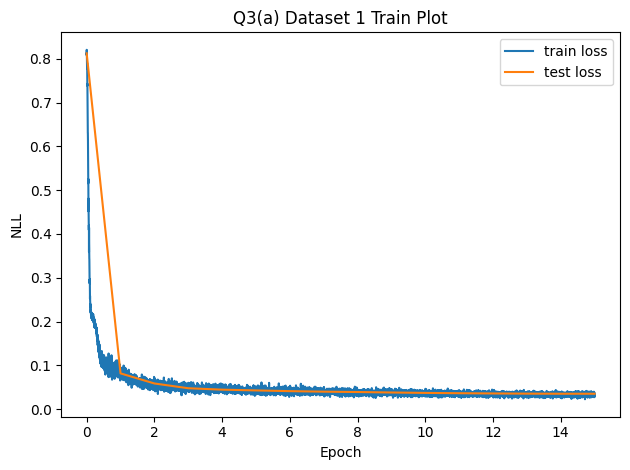

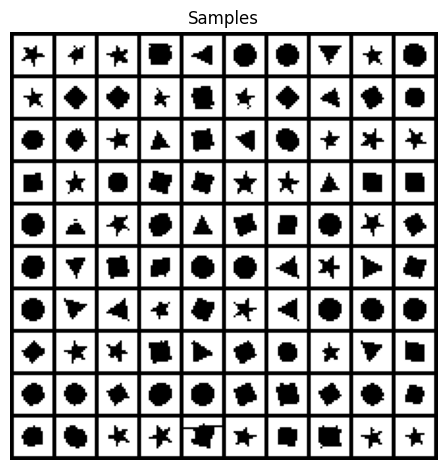

In [ ]:
q3ab_save_results(1, 'a', q3_a)

In [ ]:
q3ab_save_results(2, 'a', q3_a)

Initial Test NLL: 0.9423


KeyboardInterrupt: 

## Part (b) iGPT on Colored Shapes and MNIST

Now, implement an iGPT that models color. In order to reduce the length of token sequences, iGPT models each RGB pixel as a **single** token. This effectively reduces the context length from H*W*C to just H*W. iGPT does this through a k-means clustering approach. Because our images only each can only take on 4 values (2 bits) per channel, we can represent each pixel with 64 values (6 bits). Convert the dataset into an image of tokens and train iGPT on the colored shapes and MNIST dataset.

Checkout the iGPT paper for more details: [Generative Pretraining from Pixels](https://cdn.openai.com/papers/Generative_Pretraining_from_Pixels_V2.pdf)

Training times and hyperparameter settings should be the same as part (a), except train for longer (15 epochs)

**You will provide these deliverables**

1.   Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2.   Report the final test set performance of your final model
3. 100 samples from the final trained model


In [ ]:
import numpy as np
import torch
def images_to_tokens(image, device):
  """
  images: (N, H, W, C), uint8
  return: (N, H*W), torch.long
  """
  x = torch.as_tensor(image, dtype=torch.long, device=device)

  N, H, W, C = x.shape

  # every channel has {0, 1, 2, 3}
  assert x.min() >= 0 and x.max() <= 3

  # RGB: (R, G, B) has 0~63 integers map
  weights = torch.tensor([4 ** (C - 1 - i) for i in range(C)], device=device)

  tokens = (x * weights).sum(dim=-1)

  return tokens.reshape(N, H * W)


In [ ]:
import numpy as np
import torch

def tokens_to_images(tokens, image_shape):
    """
    Convert discrete image tokens back into the original images.

    Args:
        tokens: Token sequences with shape (N, H*W).
        image_shape: Tuple (H, W, C) describing the image dimensions.

    Returns:
        images: Reconstructed images with shape (N, H, W, C),
                represented as a numpy.uint8 array.
    """

    H, W, C = image_shape

    tokens = torch.as_tensor(tokens, dtype=torch.long)

    channels = []

    for i in range(C):

        # Calculate the positional divisor for each channel
        divisor = 4 ** (C - 1 - i)

        # Decode the corresponding channel value
        channel = (tokens // divisor) % 4

        channels.append(channel)

    # Stack channels along the last dimension
    images = torch.stack(channels, dim=-1)

    # Restore the original image dimensions
    images = images.reshape(-1, H, W, C)

    return images.detach().cpu().numpy().astype(np.uint8)



In [ ]:
# Test
toy_images = np.random.randint(
    0,
    4,
    size=(2, 4, 4, 3),
    dtype=np.uint8
)

# Images -> Token
toy_tokens = images_to_tokens(toy_images, "cpu")

# Token -> Images
reconstructed = tokens_to_images(
    toy_tokens,
    (4, 4, 3)
)

print("Original shape:", toy_images.shape)
print("Token shape:", toy_tokens.shape)
print("Reconstructed shape:", reconstructed.shape)

assert np.array_equal(toy_images, reconstructed)

print("Test passed!")

Original shape: (2, 4, 4, 3)
Token shape: torch.Size([2, 16])
Reconstructed shape: (2, 4, 4, 3)
Test passed!


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class CausalSelfAttention(nn.Module):

  def __init__(self, d_model=128, num_heads=4, max_seq_len=784):
    super().__init__()

    assert d_model % num_heads == 0

    self.d_model = d_model
    self.num_heads = num_heads
    self.head_dim = d_model // num_heads

    # Q, K, V
    self.q_proj = nn.Linear(d_model, d_model)
    self.k_proj = nn.Linear(d_model, d_model)
    self.v_proj = nn.Linear(d_model, d_model)

    self.out_proj = nn.Linear(d_model, d_model)

    # Mask
    mask = torch.triu(torch.ones(max_seq_len, max_seq_len, dtype=torch.bool), diagonal=1)

    self.register_buffer("causal_mask", mask)


  def forward(self, x):

    B, L, D = x.shape

    # Q, K, V
    q = self.q_proj(x)
    k = self.k_proj(x)
    v = self.v_proj(x)

    # (B, L, D) -> (B, heads, L, head_dim)
    q = q.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    k = k.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    v = v.view(
        B, L, self.num_heads, self.head_dim
    ).transpose(1, 2)

    # Attention Score
    scores = torch.matmul(q, k.transpose(-1, -2)) / math.sqrt(self.head_dim)

    # Mask
    mask = self.causal_mask[:L, :L]

    scores = scores.masked_fill(mask, float("-inf"))

    # Softmax
    attn_weights = torch.softmax(scores, dim=-1)

    out = torch.matmul(attn_weights, v)

    # merge heads
    out = out.transpose(1, 2).contiguous()
    out = out.view(B, L, D)

    out = self.out_proj(out)

    return out



In [ ]:
class TransformerBlock(nn.Module):

  def __init__(
      self,
      d_model=128,
      num_heads=4,
      max_seq_len=784
  ):

    super().__init__()

    self.ln1 = nn.LayerNorm(d_model)

    self.attention = CausalSelfAttention(d_model=d_model, num_heads=num_heads, max_seq_len=max_seq_len)

    self.ln2 = nn.LayerNorm(d_model)

    # FFN
    self.mlp = nn.Sequential(nn.Linear(d_model, 4*d_model), nn.GELU(), nn.Linear(4*d_model, d_model))

  def forward(self, x):

    x = x + self.attention(self.ln1(x))

    x = x + self.mlp(self.ln2(x))

    return x



In [ ]:
class AutoregressiveTransformer(nn.Module):

  def __init__(
      self,
      max_seq_len,
      vocab_size,
      d_model=128,
      num_heads=4,
      num_layers=2
  ):
    super().__init__()

    self.max_seq_len = max_seq_len
    self.vocab_size = vocab_size

    self.bos_token = vocab_size

    # Token Embedding
    self.token_embedding = nn.Embedding(
      num_embeddings=vocab_size + 1,
      embedding_dim=d_model
    )

    # Learned Positional Embedding
    self.position_embedding = nn.Embedding(
        num_embeddings=max_seq_len,
        embedding_dim=d_model
    )

    # Transformer Blocks

    self.blocks = nn.ModuleList([
      TransformerBlock(
          d_model=d_model,
          num_heads=num_heads,
          max_seq_len=max_seq_len
      )
      for _ in range(num_layers)
    ])

    # Final LayerNorm
    self.ln_f = nn.LayerNorm(d_model)
    self.head = nn.Linear(
        d_model,
        vocab_size
    )


  def forward(self, input_ids):

      B, L = input_ids.shape

      assert L <= self.max_seq_len

      # 1. Token Embedding
      token_emb = self.token_embedding(input_ids)

      # 2. Position Embedding
      positions = torch.arange(
          L,
          device=input_ids.device
      )

      pos_emb = self.position_embedding(positions)

      # 3. Combine Embeddings
      x = token_emb + pos_emb

      # 4. Transformer Blocks
      for block in self.blocks:
          x = block(x)

      # 5. Final LayerNorm
      x = self.ln_f(x)

      # 6. Output Head
      logits = self.head(x)

      return logits

In [ ]:
def make_autoregressive_input(pixels, bos_token):
    """

    Args:
        pixels: (B, L)，真实图像 Token
        bos_token: BOS Token ID

    Returns:
        input_ids: (B, L)
        targets:   (B, L)
    """

    pixels = pixels.to(dtype=torch.long)

    B = pixels.shape[0]

    bos = torch.full(
        (B, 1),
        bos_token,
        dtype=torch.long,
        device=pixels.device
    )

    input_ids = torch.cat(
        [bos, pixels[:, :-1]],
        dim=1
    )

    targets = pixels

    return input_ids, targets

In [ ]:
def compute_nll_per_dim(logits, targets, vocab_size, channels):
    """
    Compute the average negative log-likelihood per image dimension.

    Args:
        logits: Model predictions with shape (B, L, V).
        targets: Ground-truth token IDs with shape (B, L).
        vocab_size: Number of possible image tokens.
        channels: Number of image channels.

    Returns:
        loss: Scalar tensor representing the average NLL in nats/dim.
    """

    # Merge batch and sequence dimensions
    logits = logits.reshape(-1, vocab_size)
    targets = targets.reshape(-1)

    # Compute the average cross-entropy loss
    loss = F.cross_entropy(
        logits,
        targets,
        reduction="mean"
    )

    # Normalize by the number of image channels
    loss = loss / channels

    return loss

In [ ]:
@torch.no_grad()
def evaluate_igpt_nll(
    model,
    test_loader,
    device,
    vocab_size,
    bos_token,
    channels
):
    """
    Evaluate the average negative log-likelihood per dimension
    over the entire test dataset.

    Args:
        model: The autoregressive image generation model.
        test_loader: DataLoader containing the test dataset.
        device: Device used for computation (CPU or CUDA).
        vocab_size: Number of possible image tokens.
        bos_token: Token ID used for the beginning-of-sequence token.
        channels: Number of image channels.

    Returns:
        test_nll: Average negative log-likelihood in nats/dim
                  over the entire test dataset.
    """

    model.eval()

    total_nll = 0.0
    total_dim = 0

    for (pixels,) in test_loader:

        pixels = pixels.to(
            device=device,
            dtype=torch.long
        )

        # Construct autoregressive inputs and targets
        input_ids, targets = make_autoregressive_input(
            pixels,
            bos_token
        )

        # Forward pass
        logits = model(input_ids)

        # Compute the sum of negative log-likelihoods
        loss_sum = F.cross_entropy(
            logits.reshape(-1, vocab_size),
            targets.reshape(-1),
            reduction="sum"
        )

        total_nll += loss_sum.item()

        # Count the total number of image dimensions
        total_dim += targets.numel() * channels

    # Compute the average NLL per image dimension
    test_nll = total_nll / total_dim

    return test_nll

In [ ]:

def train_igpt(
    model,
    train_loader,
    test_loader,
    device,
    vocab_size,
    bos_token,
    channels,
    num_epochs=15,
    lr=1e-3
):
    """
    Train an autoregressive image generation model.

    Args:
        model: The autoregressive Transformer model.
        train_loader: DataLoader containing training tokens.
        test_loader: DataLoader containing testing tokens.
        device: Device used for computation (CPU or CUDA).
        vocab_size: Number of possible image tokens.
        bos_token: Token ID used for the beginning-of-sequence token.
        channels: Number of image channels.
        num_epochs: Number of training epochs.
        lr: Initial learning rate.

    Returns:
        model: The trained autoregressive Transformer.
        train_losses: Training NLL/dim recorded at every minibatch.
        test_losses: Test NLL/dim evaluated at initialization
                     and after each training epoch.
    """

    # =====================================
    # 1. Initialize Optimizer
    # =====================================

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    # =====================================
    # 2. Initialize Learning Rate Scheduler
    # =====================================

    total_steps = num_epochs * len(train_loader)

    warmup_steps = min(
        1000,
        max(1, total_steps // 10)
    )

    def lr_lambda(current_step):

        # Linear Warmup
        if current_step < warmup_steps:
            return float(current_step + 1) / warmup_steps

        # Cosine Decay
        progress = (
            current_step - warmup_steps
        ) / max(
            1,
            total_steps - warmup_steps
        )

        progress = min(max(progress, 0.0), 1.0)

        return 0.5 * (
            1.0 + math.cos(math.pi * progress)
        )

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda
    )

    # =====================================
    # 3. Evaluate Before Training
    # =====================================

    test_losses = []

    initial_test_loss = evaluate_igpt_nll(
        model=model,
        test_loader=test_loader,
        device=device,
        vocab_size=vocab_size,
        bos_token=bos_token,
        channels=channels
    )

    test_losses.append(initial_test_loss)

    print(
        f"Initial Test NLL/dim: {initial_test_loss:.4f}"
    )

    # =====================================
    # 4. Training
    # =====================================

    train_losses = []

    for epoch in range(num_epochs):

        model.train()

        epoch_losses = []

        for (pixels,) in train_loader:

            pixels = pixels.to(
                device=device,
                dtype=torch.long
            )

            # Construct autoregressive inputs and targets
            input_ids, targets = make_autoregressive_input(
                pixels,
                bos_token
            )

            # Clear gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            logits = model(input_ids)

            # Compute average NLL per image dimension
            loss = compute_nll_per_dim(
                logits=logits,
                targets=targets,
                vocab_size=vocab_size,
                channels=channels
            )

            # Backward pass
            loss.backward()

            # Update model parameters
            optimizer.step()

            # Update learning rate
            scheduler.step()

            # Record minibatch training loss
            loss_value = loss.item()

            train_losses.append(loss_value)
            epoch_losses.append(loss_value)

        # =================================
        # 5. Evaluate After Each Epoch
        # =================================

        test_loss = evaluate_igpt_nll(
            model=model,
            test_loader=test_loader,
            device=device,
            vocab_size=vocab_size,
            bos_token=bos_token,
            channels=channels
        )

        test_losses.append(test_loss)

        # Compute average training loss for this epoch
        epoch_train_loss = np.mean(epoch_losses)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train NLL/dim: {epoch_train_loss:.4f} "
            f"Test NLL/dim: {test_loss:.4f} "
            f"LR: {optimizer.param_groups[0]['lr']:.6f}"
        )

    # =====================================
    # 6. Return Results
    # =====================================

    return (
        model,
        np.array(train_losses),
        np.array(test_losses)
    )


In [ ]:

@torch.no_grad()
def sample_igpt_images(
    model,
    num_samples,
    image_shape,
    device,
    bos_token,
    sample_batch_size=8
):
    """
    Generate images autoregressively using the trained iGPT model.

    Args:
        model: The trained autoregressive Transformer.
        num_samples: Number of images to generate.
        image_shape: Tuple (H, W, C) describing the image dimensions.
        device: Device used for computation (CPU or CUDA).
        bos_token: Token ID used for the beginning-of-sequence token.
        sample_batch_size: Number of images generated in each batch.

    Returns:
        samples: Generated images with shape (num_samples, H, W, C),
                 represented as a numpy.uint8 array.
    """

    model.eval()

    H, W, C = image_shape

    # Each pixel is represented by a single token
    seq_len = H * W

    all_samples = []

    # Generate images in batches to reduce memory consumption
    for start in range(0, num_samples, sample_batch_size):

        current_batch = min(
            sample_batch_size,
            num_samples - start
        )

        # Allocate space for BOS and generated tokens
        generated = torch.empty(
            current_batch,
            seq_len + 1,
            dtype=torch.long,
            device=device
        )

        # Initialize the sequence with BOS
        generated[:, 0] = bos_token

        # Autoregressively generate one token at a time
        for t in range(seq_len):

            # Use only the already generated prefix
            input_ids = generated[:, :t + 1]

            # Forward pass
            logits = model(input_ids)

            # Get predictions for the next token
            next_logits = logits[:, -1, :]

            # Convert logits into probabilities
            probs = torch.softmax(
                next_logits,
                dim=-1
            )

            # Sample the next token
            next_token = torch.multinomial(
                probs,
                num_samples=1
            )

            # Append the sampled token to the sequence
            generated[:, t + 1] = next_token.squeeze(1)

        # Remove the BOS token
        pixels = generated[:, 1:]

        # Convert tokens back to images
        images = tokens_to_images(
            pixels,
            image_shape
        )

        all_samples.append(images)

    # Concatenate all generated batches
    samples = np.concatenate(
        all_samples,
        axis=0
    )

    return samples


In [ ]:
from torch.utils.data import DataLoader, TensorDataset
def q3_b(train_data, test_data, image_shape, dset_id):
    """
    Train an autoregressive image generation model (iGPT).

    Args:
        train_data: Training images with shape (N, H, W, C),
                    containing values in {0, 1, 2, 3}.
        test_data: Test images with shape (N, H, W, C),
                   containing values in {0, 1, 2, 3}.
        image_shape: Tuple (H, W, C) describing image dimensions.
        dset_id: Dataset identifier (1 or 2).

    Returns:
        train_losses: Numpy array of training NLL/dim values,
                      recorded after every minibatch.
        test_losses: Numpy array of test NLL/dim values,
                     evaluated at initialization and after each epoch.
        samples: Numpy array of 100 generated images with shape
                 (100, H, W, C) and dtype uint8.
    """

    # =====================================
    # 1. Hyperparameters
    # =====================================

    device = torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )

    batch_size = 16
    num_epochs = 15

    d_model = 128
    num_heads = 4
    num_layers = 2

    lr = 1e-3

    # =====================================
    # 2. Validate Input Data
    # =====================================

    H, W, C = image_shape

    assert train_data.ndim == 4
    assert test_data.ndim == 4

    assert tuple(train_data.shape[1:]) == tuple(image_shape)
    assert tuple(test_data.shape[1:]) == tuple(image_shape)

    assert train_data.min() >= 0
    assert train_data.max() <= 3

    assert test_data.min() >= 0
    assert test_data.max() <= 3

    # =====================================
    # 3. Determine Token Vocabulary
    # =====================================

    base = 4

    # Each pixel is represented by one token
    vocab_size = base ** C

    # Reserve one additional token for BOS
    bos_token = vocab_size

    # Each spatial pixel corresponds to one token
    max_seq_len = H * W

    print("=====================================")
    print("Dataset ID:", dset_id)
    print("Image shape:", image_shape)
    print("Vocabulary size:", vocab_size)
    print("BOS token:", bos_token)
    print("Sequence length:", max_seq_len)
    print("Device:", device)
    print("=====================================")

    # =====================================
    # 4. Convert Images into Tokens
    # =====================================

    train_tokens = images_to_tokens(train_data, device)
    test_tokens = images_to_tokens(test_data, device)

    print("Train tokens shape:", train_tokens.shape)
    print("Test tokens shape:", test_tokens.shape)

    # =====================================
    # 5. Create DataLoaders
    # =====================================

    train_loader = DataLoader(
        TensorDataset(train_tokens),
        batch_size=batch_size,
        shuffle=True
    )

    test_loader = DataLoader(
        TensorDataset(test_tokens),
        batch_size=batch_size,
        shuffle=False
    )

    # =====================================
    # 6. Initialize Model
    # =====================================

    model = AutoregressiveTransformer(
        max_seq_len=max_seq_len,
        vocab_size=vocab_size,
        d_model=d_model,
        num_heads=num_heads,
        num_layers=num_layers
    ).to(device)

    # =====================================
    # 7. Train Model
    # =====================================

    model, train_losses, test_losses = train_igpt(
        model=model,
        train_loader=train_loader,
        test_loader=test_loader,
        device=device,
        vocab_size=vocab_size,
        bos_token=bos_token,
        channels=C,
        num_epochs=num_epochs,
        lr=lr
    )

    # =====================================
    # 8. Generate 100 Samples
    # =====================================

    samples = sample_igpt_images(
        model=model,
        num_samples=100,
        image_shape=image_shape,
        device=device,
        bos_token=bos_token,
        sample_batch_size=8
    )

    # =====================================
    # 9. Validate Outputs
    # =====================================

    assert train_losses.shape[0] == (
        num_epochs * len(train_loader)
    )

    assert test_losses.shape[0] == num_epochs + 1

    assert samples.shape == (
        100,
        H,
        W,
        C
    )

    assert samples.dtype == np.uint8

    assert samples.min() >= 0
    assert samples.max() <= 3

    print("=====================================")
    print("Training completed!")
    print("Final Test NLL/dim:", test_losses[-1])
    print("Train losses:", train_losses.shape)
    print("Test losses:", test_losses.shape)
    print("Generated samples:", samples.shape)
    print("=====================================")

    # =====================================
    # 10. Return Deliverables
    # =====================================

    return train_losses, test_losses, samples


### Results

Once you've implemented `q3_b`, execute the cells below to visualize and save your results

Dataset ID: 1
Image shape: (20, 20, 3)
Vocabulary size: 64
BOS token: 64
Sequence length: 400
Device: cuda
Train tokens shape: torch.Size([10479, 400])
Test tokens shape: torch.Size([4491, 400])
Initial Test NLL/dim: 1.4517
Epoch [1/15] Train NLL/dim: 0.3872 Test NLL/dim: 0.0478 LR: 0.000668
Epoch [2/15] Train NLL/dim: 0.0381 Test NLL/dim: 0.0327 LR: 0.000997
Epoch [3/15] Train NLL/dim: 0.0294 Test NLL/dim: 0.0273 LR: 0.000970
Epoch [4/15] Train NLL/dim: 0.0262 Test NLL/dim: 0.0254 LR: 0.000918
Epoch [5/15] Train NLL/dim: 0.0242 Test NLL/dim: 0.0238 LR: 0.000843
Epoch [6/15] Train NLL/dim: 0.0228 Test NLL/dim: 0.0224 LR: 0.000750
Epoch [7/15] Train NLL/dim: 0.0216 Test NLL/dim: 0.0214 LR: 0.000643
Epoch [8/15] Train NLL/dim: 0.0206 Test NLL/dim: 0.0208 LR: 0.000529
Epoch [9/15] Train NLL/dim: 0.0198 Test NLL/dim: 0.0201 LR: 0.000413
Epoch [10/15] Train NLL/dim: 0.0191 Test NLL/dim: 0.0197 LR: 0.000302
Epoch [11/15] Train NLL/dim: 0.0184 Test NLL/dim: 0.0193 LR: 0.000201
Epoch [12/15] T

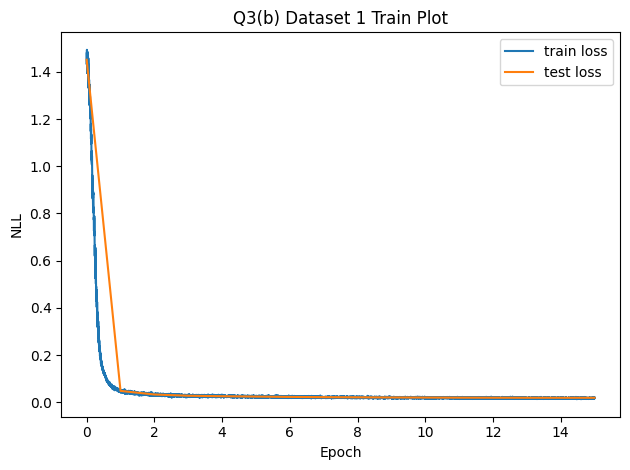

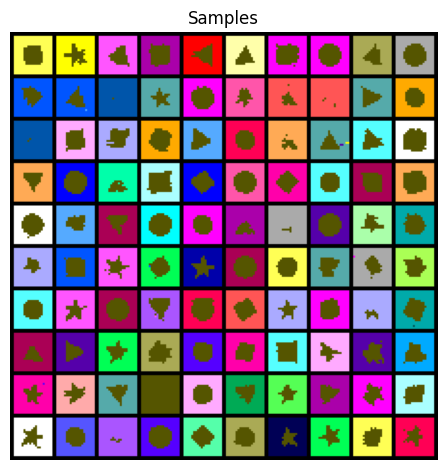

In [ ]:
q3ab_save_results(1, 'b', q3_b)

In [ ]:
q3ab_save_results(2, 'b', q3_b)

Dataset ID: 2
Image shape: (28, 28, 3)
Vocabulary size: 64
BOS token: 64
Sequence length: 784
Device: cuda
Train tokens shape: torch.Size([60000, 784])
Test tokens shape: torch.Size([10000, 784])


KeyboardInterrupt: 

## Part (c) K, V Caching for Improved Inference
You may have noticed that generation from the transformer is quite slow. Part of this is just due to the autoregressive nature. However, another part is due to some computational inefficiency. At each forward pass of the model, we are performing repeat computation of the past sequence. Specifically, we can cache the key and values at the multi attention layer to more quickly predict at each step.

In self-attention, a sequence is processed by generating three vectors for each element in the sequence: a Query (Q), a Key (K), and a Value (V). These vectors are then used to compute attention scores and subsequently the output of the attention layer.
Mathematically, this can be represented as:
 * For each index $i$, compute $Q_i$, $K_i$, $V_i$ for the current element
 * Retrieve $K_{<i}$ and $V_{<i}$ from the cache (where $<i$ denotes all indices before the current one)
 * Compute the attention output using $Q_i$, $[K_{<i}, K_i]$, $[V_{<i}, V_i]$


Next implement caching for your transformer to make inference more efficient by modifying your self attention. Use caching for inference in the future problems for faster generation! (Note caching is only used during inference). You will use the same dataset as in part B, dataset 2 of this question (colored mnist). No training is required in this section, feel free to reuse the model you trained in part B, dataset 2.

**You will provide these deliverables**

1. Over the course of inference, measure the time for the forward pass over the total sequence length with and without caching.
3. 100 samples from the final trained model using the caching inference pipeline.



In [ ]:
def q3_c(train_data, test_data, image_shape, dset_id):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: (H, W, C), height, width, and # of channels of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets

  Returns
  - a (# sampling steps,) numpy array of time per sampling iteration, without caching
  - a (# sampling steps,) numpy array of time per sampling iteration, with without caching
  - a numpy array of size (100, H, C, W) of samples with values in {0, 1, 2, 3} (sample generated without caching)
  - a numpy array of size (100, H, C, W) of samples with values in {0, 1, 2, 3} (sample generated with caching)
  """
  # understand, ignore this question
  return time_list_no_cache, time_list_with_cache, samples_no_cache, samples_with_cache

### Results

Once you've implemented `q3_c`, execute the cells below to visualize and save your results



In [ ]:
q3c_save_results(2, q3_c)

# Question 4: Causal Transformer: Tokenized Images

## Image Tokenization with Vector Quanization

## Part (a) Image Quantization

Above, we implemented iGPT, which autoregressivly predicts raw pixels. Transformers have quadratic complexity in the sequence length which prevents this naive approach from scaling well to large images.

The space of natural images often contains very correlated information. This suggests we can learn a reduced representation. VQVAE is a method that does just that, learning to map images to a more compact discrete set of tokens. We will cover this method in more detail in future lectures. The only thing you need to know now is that we can learn an encoder (and corresponding decoder), which can extract a discrete representation from an image.

If you are curious, checkout the VQVAE paper to learn more: https://arxiv.org/abs/1711.00937 (we will cover this in a future lecture though!)

In this part, we provide a pre-trained VQVAE model, which consists of:
 * encoder to tokenize the images
 * the decoder to recover the image
 * a token vocabulary of VQVAE_MODEL.n_embeddings

Below is the code for loading the VQ model. Note that VQVAE encoding process is lossy, so the decoded images will not be the exact same as the input. Some blurriness in the recovered image is to be expected. The docstrings of the relevant methods you will need for the VQVAE_MODEL are provided below for your convenience.

We will use 2 colored mnist datasets in this part. The first is the same dataset used in previous parts. The second, hads a colored digit on a differently colored background. We will call these datasets Colored MNIST and Colored MNIST v2. Note that the vqvae is trained per dataset.

**You will provide these deliverables**

1. Use the provided encoder model to quantize the images then inspect the recovered images by applying the decoder for each of the two datasets

In [1]:
# @property
# def n_embeddings(self) -> int:
#     """The size of the token vocabulary"""
#
# def quantize(self, x: np.ndarray) -> np.ndarray:
#     """Quantize an image x.
#
#     Args:
#         x (np.ndarray, dtype=int): Image to quantize. shape=(batch_size, 28, 28, 3). Values in [0, 3].
#
#     Returns:
#         np.ndarray: Quantized image. shape=(batch_size, 7, 7). Values in [0, n_embeddings]
#     """
#
# def decode(self, z_index: np.ndarray) -> np.ndarray:
#     """Decode a quantized image.
#
#     Args:
#         z_index (np.ndarray, dtype=int): Quantized image. shape=(batch_size, 7, 7). Values in [0, n_embeddings].
#
#     Returns:
#         np.ndarray: Decoded image. shape=(batch_size, 28, 28, 3). Values in [0, 3].
#     """
#

In [9]:
def q4_a(images, vqvae):
  """
  images: (B, H, W, C), the images to pass through the encoder and decoder of the vqvae
  vqvae: a vqvae model, trained on the relevant dataset

  Returns
  - a numpy array of size (2, H, W, C) of the decoded image
  """
  # Convert the input into a Numpy array
  images = np.asarray(images)

  # Check the input dimension
  assert images.ndim == 4
  assert images.shape[0] >= 2

  # Select the first two images
  images = images[:2].astype(np.int64, copy=False)

  # Check the image value range
  assert images.min() >= 0
  assert images.max() <= 3

  # Quantize the images into discrete token indices
  z_index = vqvae.quantize(images)

  # Decoder the quantized token indices into reconstructed images
  autoencoded_images = vqvae.decode(z_index)

  # Convert the output into a NumPy array
  autoencoded_images = np.asarray(autoencoded_images)

  # Check the reconstructed image shape
  assert autoencoded_images.shape == images.shape

  return autoencoded_images

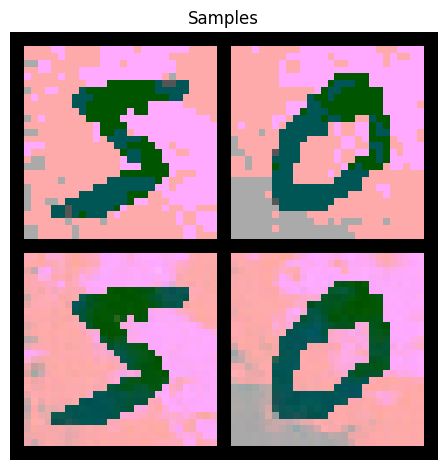

In [10]:
q4a_save_results(1, q4_a)

In [ ]:
q4a_save_results(2, q4_a)

## Part (b) Autoregressive Transformer on Colored Shapes and MNIST with Vector Quantization

We can use the VQVAE to tokenize an image dataset. This will result in a much smaller sequence length than the approach we tried in Question 3(b). For this part, train a transformer on the dataset tokenized by the VQVAE.

This is a simplified version of the approach used in VQGAN [VQGAN](https://arxiv.org/abs/2012.09841) -> Section 3.2: Learning the Composition of Images with Transformers (Again, we will cover this in more detail in a future lecture!)

Update the following hyperparameters:
* layers: 4 (we can train a bigger transformer now since less memory is used per input!)
* 30 epochs

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 100 samples from the final trained model

In [ ]:
def q4_b(train_data, test_data, image_shape, dset_id, vqvae):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: (H, W, C), height, width, and # of channels of the image
  dset_id: An identifying number of which dataset is given (1 or 2). Most likely
           used to set different hyperparameters for different datasets
  vqvae: a vqvae model, trained on dataset dset_id

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a numpy array of size (100, H, C, W) of samples with values in {0, 1, 2, 3}
  """
  return train_losses, test_losses, samples

### Results

Once you've implemented `q4_b`, execute the cells below to visualize and save your results



In [ ]:
q4b_save_results(1, q4_b)

In [ ]:
q4b_save_results(2, q4_b)

# Question 5: Causal Transformer: Text

Now lets consider text! You are probably already fimilar with autoregressive transformers for text, now more commonly known as Large Language Modesl (LLMs).
We will now implement a simplified version.

We will be detailing with a [small poetry dataset](https://huggingface.co/datasets/merve/poetry). See some of the data below.

In [ ]:
data = visualize_q5_data()

## Part (a) Modeling Text
Train a transformer on the poetry dataset.

Data Preprocessing:
* We will use a simple method to tokenize the data. We will convert each unique character into a token. (Current LLMs use more sophisticated tokenizers, most commonly, [byte-pair encoding](https://huggingface.co/learn/nlp-course/chapter6/5?fw=pt))
* Previously we have leveraged a **\<bos\>** as part of the model, just like iGPT. For text, we may not always sample a sequence that starts at the beginning. Instead, we will add the **\<bos\>** token to the beginning of every sequence in the dataset, and remove the **\<bos\>** token from the model.
* Another problem is that the model must know when to stop sampling. This is done by appending an **\<eos\>**, or end of sequence token at the end of every sequence in the dataset.
* We can now convert the sequence into subsequences of size context_length, for training!

We recommend the following hyperparameters:
* Sequence length: 128
* 5 epochs

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. Provide **5 unconditional samples** of **128 characters** showcasing the model text generation capabilities (text samples should stop after **\<eos\>**. Text after **\<eos\>** can be removed in post processing)

In [ ]:
import torch.utils.data as data
def q5_a(train_text, test_text):
  """
  train_text: list[str] Train text sequences.
  test_text: list[str] Test text sequences.

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a list of 5 (str), 5 generated samples from the model.
  """
  return train_losses, test_losses, text_samples

### Results

Once you've implemented `q5_a`, execute the cells below to visualize and save your results



In [ ]:
q5a_save_results(q5_a)

# Question 6: Causal Transformer: Multimodal

So far, we have been dealing only with autoregressive generation of a single modality. Now we will train a model that operates on multiple modalities!

We will use the text labeled colored MNIST dataset, which has a text description of the MNIST image. Run the cell below to visualize the data along with the text annotation. This is the Colored MNIST v2 dataset, which also comes with these text labels.

In [ ]:
visualize_q6_data()

## Part (a) Multimodal Text and Image Generation
Implement and train an autoregressive (AR) model capable of handling both text and image data. The model should be designed to process sequences composed of concatenated text and image tokens in both orders (text followed by images and images followed by text). Additionally, the model should be capable of generating unconditional text and image samples.

Data Preprocessing:
* Text Tokens: Map each unique word in the text data to a unique token. (Note that all text descriptions contain the exact same amount of words. This simplifies text processing, as you won't have to deal with sequences of different lengths as in Question 5)
* Image Tokens: Quantize the image data into tokens using the VQVAE tokenizer from Problem 4.
* In this problem, we have 2 modalities. Introduce an **\<end of text\>** token and an **\<end of image\>** token. After seeing such a token, the model should switch to sampling the next modality.
* Formulate batches as sequences of concat([**\<end of image\>**, text_tokens, **\<end of text\>**, image_tokens]) and concat([**\<end of text\>**, image_tokens, **\<end of image\>**, text_tokens]). With a 50/50 split between each ordering.

Inference:
* During inference, we cannot mix modality tokens. During sampling we can restrict the logits to only be within the relevant modality.
* After **\<end of image\>**, only allow the model to sample text tokens (including **\<end of text\>**)
* After **\<end of text\>**, only allow the model to sample image tokens (including **\<end of image\>**)
* At the very start (conditioned on the **\<bos\>** token, only allow the model to sample one of (**\<end of image\>** or **\<end of text\>**))
* As the model may not always correctly sample the **\<end of image\>** token before the image ends, you may add a rule to force the model to always sample the correct number of image tokens (49 tokens).

You can use the same hyperparameters as in 4(b) (but of course, feel free to tune your model to achieve better performance)

**You will provide these deliverables**

1. Over the course of training, record the average negative log-likelihood (nats / dim) of the training data (per minibatch) and test data (for your entire test set). Code is provided that automatically plots the training curves.
2. Report the final test set performance of your final model
3. 9 conditional samples based on provided text.
4. 9 conditional samples based on provided images.
5. 9 unconditional samples showcasing the model's capability in generating standalone text and images.

In [ ]:
def q6_a(train_data, test_data, image_shape, train_text, test_text, image_test_prompt, text_test_prompt, vqvae):
  """
  train_data: A (n_train, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  test_data: A (n_test, H, W, C) uint8 numpy array of color images with values in {0, 1, 2, 3}
  image_shape: tuple (H, W, C) The shape of the images in the dataset, indicating height, width, and number of color channels.
  train_text: list[str] Text data associated with each training image.
  test_text: list[str] Text data associated with each test image.
  image_test_prompt: (9, H, W, C) Image data used for generating conditional text samples during testing.
  text_test_prompt: list of 9 strings Text prompts used for generating conditional image samples during testing.
  vqvae: a vqvae model, trained on the relevant dataset

  Returns
  - a (# of training iterations,) numpy array of train_losses evaluated every minibatch
  - a (# of epochs + 1,) numpy array of test_losses evaluated once at initialization and after each epoch
  - a list of 9 (image, text), corresponding to the image conditioned samples
  - a list of 9 (image, text), corresponding to the text conditions samples
  - a list of 9 (image, text), corresponding to unconditional samples
  """
  return train_losses, test_losses, samples_image_conditioned, samples_text_conditioned, samples_unconditioned

### Results

Once you've implemented `q6_a`, execute the cells below to visualize and save your results



In [ ]:
q6a_save_results(q6_a)